# Overnight tests T13-T14: comparison of the results

**notebook version**: `1` (8 Nov 2026)

## ℹ️ About this notebook

Compares the outputs of the test notebooks T13 and T14, run overnight with `run_tests_T13-T14.sh`, with
the product run of the chain (run of 4 Nov 2026) and with test T4. The tests follow the investigation
of the too small daytime uptake of the LI-7500 years (plan item 25):

| Test | Notebooks | Change against the product run |
|---|---|---|
| T4 | `IRGA75/T4_01`, `T4_05` | daytime heating part of opco scaled by 0.84 in every year (6 Nov 2026) |
| T13 | `IRGA75/T13_01`, `T13_05` | daytime heating part scaled by 0.76 before 2008 and by 0.84 from 2008 |
| T14 | `IRGA75/T14_01`, `T14_05` | daytime CO2 covariance of 2004-2007 divided by a gain per year from the matched summer middays (upper bound of an instrumental cause) |

For the LI-7500 the product fill `_gfXGWN` is compared, for the LI-7200 the plain XGBoost fill `_gfXG`,
as in the product. A test whose output file is missing (not run, or failed) is left out and reported.

## ⚙️ Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
STAGE = DATADIR / '30_FLUX_POST-PROCESSING_CHAIN'

RUNS = {
    'IRGA75 product': ('IRGA75', STAGE / 'IRGA75' / '05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet'),
    'T4 heat day 0.84': ('IRGA75', STAGE / 'IRGA75' / 'T4_05_FPPC_IRGA75_NEE_OPCO_HEATDAY084_2004-2017.parquet'),
    'T13 heat day 0.76 / 0.84': ('IRGA75', STAGE / 'IRGA75' / 'T13_05_FPPC_IRGA75_NEE_OPCO_HEATDAYPERIOD_2004-2017.parquet'),
    'T14 covariance gain': ('IRGA75', STAGE / 'IRGA75' / 'T14_05_FPPC_IRGA75_NEE_OPCO_COVGAIN_2004-2017.parquet'),
    'IRGA72 product': ('IRGA72', STAGE / 'IRGA72' / '05_FPPC_IRGA72_NEE_2016-2026.09.parquet'),
}
TEST_RUNS = ['IRGA75 product', 'T4 heat day 0.84', 'T13 heat day 0.76 / 0.84', 'T14 covariance gain']

FILL = {'IRGA75': '_gfXGWN', 'IRGA72': '_gfXG'}
SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']
YEARS = {'IRGA75': range(2004, 2018), 'IRGA72': range(2016, 2026)}
PERIODS = {'2004-2006': (2004, 2006), '2007-2009': (2007, 2009), '2010-2015': (2010, 2015),
           '2016-2017': (2016, 2017), '2005-2009': (2005, 2009)}
REF_YEARS = (2016, 2025)
PARALLEL = ('2016-01-11', '2017-12-12')
DT_FIRST_YEAR = 2006
GROWING = (5, 6, 7, 8, 9, 10)  # May-Oct

# Etzold et al. (2011), mean annual NEE 2005-2009 and its range, as declared in
# 90_OVERVIEW/FLUX_NEE_IRGA75_COMPARISONS.
ETZOLD_YEARS = (2005, 2009)
ETZOLD_MEAN = -415
ETZOLD_RANGE = (-662, -366)

UMOL_TO_GC = 12.011e-6 * 1800

In [2]:
from datetime import datetime
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 200)


def tabcap(text, width=110):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")

Last run: 2026-11-08 02:43:30


## 📂 Load data

In [3]:
def columns(analyser):
    fill = FILL[analyser]
    cols = [f'NEE_L3.1_L3.3_{s}_QCF{fill}' for s in SCENARIOS] + ['NEE_L3.1_L3.3_CUT_50_QCF_gfMDS',
            'NEE_L3.1_L3.3_CUT_50_QCF', 'DAYTIME', 'GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50',
            'GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50']
    return cols


DATA, MISSING = {}, []
for label, (analyser, path) in RUNS.items():
    if not path.is_file():
        MISSING.append(label)
        continue
    df = pd.read_parquet(path, columns=columns(analyser))
    df.index = pd.DatetimeIndex(df.index)
    # Short names: NEE per scenario with the product fill, and the rest as they are.
    df = df.rename(columns={f'NEE_L3.1_L3.3_{s}_QCF{FILL[analyser]}': s for s in SCENARIOS})
    assert not df.index.duplicated().any(), f"{label}: duplicate timestamps"
    DATA[label] = df
    print(f"{label}: {path.name}, modified {datetime.fromtimestamp(path.stat().st_mtime):%Y-%m-%d %H:%M}")
print(f"\\nmissing (not run or failed): {MISSING if MISSING else 'none'}")
assert 'IRGA75 product' in DATA and 'IRGA72 product' in DATA, "a product run is missing"


def annual(label, col='CUT_50', mask=None):
    """Annual sums (gC m-2) of one column over the complete years of the run's analyser."""
    df = DATA[label]
    s = df[col] if mask is None else df[col].where(mask(df), 0.0)
    years = YEARS[RUNS[label][0]]
    return (s.groupby(df.index.year).sum() * UMOL_TO_GC).reindex(years)


def period_mean(series, period):
    lo, hi = PERIODS[period] if isinstance(period, str) else period
    return series.loc[lo:hi].mean()


REF = annual('IRGA72 product')
REF_MEAN = period_mean(REF, REF_YEARS)
print(f"LI-7200 mean annual NEE {REF_YEARS[0]}-{REF_YEARS[1]} (CUT_50): {REF_MEAN:.0f} gC m-2")

IRGA75 product: 05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet, modified 2026-11-04 16:40
T4 heat day 0.84: T4_05_FPPC_IRGA75_NEE_OPCO_HEATDAY084_2004-2017.parquet, modified 2026-11-06 19:11


T13 heat day 0.76 / 0.84: T13_05_FPPC_IRGA75_NEE_OPCO_HEATDAYPERIOD_2004-2017.parquet, modified 2026-11-08 01:45
T14 covariance gain: T14_05_FPPC_IRGA75_NEE_OPCO_COVGAIN_2004-2017.parquet, modified 2026-11-08 02:43


IRGA72 product: 05_FPPC_IRGA72_NEE_2016-2026.09.parquet, modified 2026-11-04 15:46
\nmissing (not run or failed): none
LI-7200 mean annual NEE 2016-2025 (CUT_50): -23 gC m-2


## 1. Annual sums

### 📋 Table: annual NEE of the LI-7500 per run

In [4]:
ann = pd.DataFrame({l: annual(l) for l in TEST_RUNS if l in DATA})
ann.index.name = 'year'
tabcap("annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 per run")
display(ann.round(0))

Table - annual NEE (gC m-2, CUT_50, product fill) of the LI-7500 per run\n


,IRGA75 product,T4 heat day 0.84,T13 heat day 0.76 / 0.84,T14 covariance gain
year,,,,
2004,248.0,136.0,87.0,-474.0
2005,275.0,183.0,138.0,-175.0
2006,457.0,368.0,324.0,87.0
2007,123.0,45.0,6.0,-443.0
2008,143.0,57.0,57.0,140.0
2009,91.0,12.0,12.0,103.0
2010,33.0,-59.0,-66.0,33.0
2011,8.0,-94.0,-89.0,10.0
2012,-36.0,-103.0,-110.0,-40.0


### 📋 Table: period means against the LI-7200 years and Etzold et al. (2011)

In [5]:
_rows = {}
for l in ann.columns:
    s = ann[l]
    _r = {p: period_mean(s, p) for p in PERIODS}
    _r.update({f"{p} minus LI-7200": period_mean(s, p) - REF_MEAN
               for p in ('2004-2006', '2007-2009', '2010-2015', '2016-2017')})
    _r['2005-2009 minus Etzold et al.'] = period_mean(s, ETZOLD_YEARS) - ETZOLD_MEAN
    _rows[l] = _r
periods = pd.DataFrame(_rows).T
tabcap(f"mean annual NEE (gC m-2) per period and run, its difference to the LI-7200 mean of "
       f"{REF_YEARS[0]}-{REF_YEARS[1]} ({REF_MEAN:.0f}) and to Etzold et al. (2011) for 2005-2009 "
       f"({ETZOLD_MEAN}, range {ETZOLD_RANGE[0]} to {ETZOLD_RANGE[1]})")
display(periods.round(0))

Table - mean annual NEE (gC m-2) per period and run, its difference to the LI-7200 mean of 2016-2025 (-23) and
to Etzold et al. (2011) for 2005-2009 (-415, range -662 to -366)\n


,2004-2006,2007-2009,2010-2015,2016-2017,2005-2009,2004-2006 minus LI-7200,2007-2009 minus LI-7200,2010-2015 minus LI-7200,2016-2017 minus LI-7200,2005-2009 minus Etzold et al.
IRGA75 product,327.0,119.0,-8.0,-83.0,218.0,349.0,142.0,15.0,-60.0,633.0
T4 heat day 0.84,229.0,38.0,-95.0,-175.0,133.0,251.0,61.0,-72.0,-152.0,548.0
T13 heat day 0.76 / 0.84,183.0,25.0,-95.0,-180.0,107.0,206.0,48.0,-72.0,-157.0,522.0
T14 covariance gain,-187.0,-67.0,-5.0,-71.0,-58.0,-165.0,-44.0,18.0,-48.0,357.0


## 2. Where the gap sits

### 📋 Table: gap to the LI-7200 by season, day and night

In [6]:
PARTS = {'May-Oct day': lambda d: d.index.month.isin(GROWING) & (d['DAYTIME'] == 1),
         'May-Oct night': lambda d: d.index.month.isin(GROWING) & (d['DAYTIME'] != 1),
         'Nov-Apr day': lambda d: ~d.index.month.isin(GROWING) & (d['DAYTIME'] == 1),
         'Nov-Apr night': lambda d: ~d.index.month.isin(GROWING) & (d['DAYTIME'] != 1)}
_ref = {k: period_mean(annual('IRGA72 product', mask=f), REF_YEARS) for k, f in PARTS.items()}
_rows = {}
for l in TEST_RUNS:
    if l not in DATA:
        continue
    _a = {k: annual(l, mask=f) for k, f in PARTS.items()}
    for p in ('2004-2006', '2007-2009', '2010-2015', '2016-2017'):
        _r = {k: period_mean(v, p) - _ref[k] for k, v in _a.items()}
        _r['total'] = sum(_r.values())
        _rows[(l, p)] = _r
gap = pd.DataFrame(_rows).T
tabcap(f"LI-7500 period mean minus the LI-7200 mean of {REF_YEARS[0]}-{REF_YEARS[1]} (gC m-2 per year, "
       f"CUT_50, product fill), by season (May-Oct, Nov-Apr) and by day and night (DAYTIME flag). LI-7200 "
       f"reference: " + ", ".join(f"{k} {v:.0f}" for k, v in _ref.items()))
display(gap.round(0))

Table - LI-7500 period mean minus the LI-7200 mean of 2016-2025 (gC m-2 per year, CUT_50, product fill), by
season (May-Oct, Nov-Apr) and by day and night (DAYTIME flag). LI-7200 reference: May-Oct day -894, May-Oct
night 472, Nov-Apr day 20, Nov-Apr night 379\n


May-Oct day  May-Oct night  Nov-Apr day  Nov-Apr night  total
IRGA75 product           2004-2006        303.0          -50.0        136.0          -40.0  349.0
                         2007-2009        136.0          -64.0         87.0          -17.0  142.0
                         2010-2015         68.0          -69.0         18.0           -3.0   15.0
                         2016-2017         66.0          -77.0         -2.0          -47.0  -60.0
T4 heat day 0.84         2004-2006        272.0          -49.0         73.0          -44.0  251.0
                         2007-2009         93.0          -64.0         48.0          -16.0   61.0
                         2010-2015         30.0          -68.0        -30.0           -4.0  -72.0
                         2016-2017         20.0          -79.0        -49.0          -45.0 -152.0
T13 heat day 0.76 / 0.84 2004-2006        262.0          -51.0         41.0          -46.0  206.0
                         2007-2009         84.0          -63.0         44.0          -17.0   48.0
                         2010-2015         31.0          -68.0        -31.0           -4.0  -72.0
                         2016-2017         15.0          -79.0        -47.0          -46.0 -157.0
T14 covariance gain      2004-2006        -57.0          -49.0        -15.0          -43.0 -165.0
                         2007-2009         -6.0          -61.0         39.0          -15.0  -44.0
                         2010-2015         67.0          -66.0         18.0           -1.0   18.0
                         2016-2017         65.0          -74.0          4.0          -43.0  -48.0

### 📋 Table: partitioning per period

In [7]:
_cols = ('GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50', 'GPP_DT_OF_CUT_50', 'RECO_DT_OF_CUT_50')
_rows = {}
for l in TEST_RUNS:
    if l not in DATA:
        continue
    for p in ('2004-2006', '2007-2009', '2010-2015', '2016-2017'):
        lo, hi = PERIODS[p]
        _rows[(l, p)] = {c: period_mean(annual(l, c), (max(lo, DT_FIRST_YEAR) if '_DT_' in c else lo, hi))
                         for c in _cols}
_rows[('LI-7200', f"{REF_YEARS[0]}-{REF_YEARS[1]}")] = {c: period_mean(annual('IRGA72 product', c), REF_YEARS)
                                                       for c in _cols}
part = pd.DataFrame(_rows).T
tabcap(f"mean annual GPP and RECO (gC m-2) of the nighttime (NT) and daytime (DT) partitioning per period "
       f"and run; the daytime method from {DT_FIRST_YEAR}")
display(part.round(0))

Table - mean annual GPP and RECO (gC m-2) of the nighttime (NT) and daytime (DT) partitioning per period and
run; the daytime method from 2006\n


GPP_NT_OF_CUT_50  RECO_NT_OF_CUT_50  GPP_DT_OF_CUT_50  RECO_DT_OF_CUT_50
IRGA75 product           2004-2006            1179.0             1505.0            1190.0             1778.0
                         2007-2009            1532.0             1651.0            1510.0             1857.0
                         2010-2015            1621.0             1612.0            1575.0             1786.0
                         2016-2017            1689.0             1606.0            1804.0             1856.0
T4 heat day 0.84         2004-2006            1274.0             1502.0            1245.0             1753.0
                         2007-2009            1614.0             1652.0            1569.0             1809.0
                         2010-2015            1710.0             1615.0            1653.0             1777.0
                         2016-2017            1782.0             1606.0            1904.0             1957.0
T13 heat day 0.76 / 0.84 2004-2006            1318.0             1500.0            1308.0             1795.0
                         2007-2009            1627.0             1652.0            1578.0             1829.0
                         2010-2015            1710.0             1615.0            1653.0             1777.0
                         2016-2017            1786.0             1606.0            1904.0             1957.0
T14 covariance gain      2004-2006            1700.0             1513.0            1670.0             2112.0
                         2007-2009            1719.0             1652.0            1731.0             1949.0
                         2010-2015            1617.0             1612.0            1575.0             1786.0
                         2016-2017            1677.0             1606.0            1804.0             1856.0
LI-7200                  2016-2025            1885.0             1863.0            2071.0             2241.0

### 📋 Table: LI-7500 minus LI-7200 in the parallel period

In [8]:
_p = slice(*PARALLEL)
_r72 = DATA['IRGA72 product'].loc[_p]
_rows = {}
for l in TEST_RUNS:
    if l not in DATA:
        continue
    _d = DATA[l].loc[_p]
    _diff = (_d['CUT_50'] - _r72['CUT_50'].reindex(_d.index)) * UMOL_TO_GC
    _day = _d['DAYTIME'] == 1
    _rows[l] = {'all half-hours': _diff.sum(), 'day': _diff[_day].sum(), 'night': _diff[~_day].sum()}
parallel = pd.DataFrame(_rows).T
tabcap(f"sum of LI-7500 minus LI-7200 NEE (gC m-2, CUT_50, product fills) over the parallel period "
       f"{PARALLEL[0]} to {PARALLEL[1]}. T13 and T14 change the flux only before 2008; differences here "
       f"to T4 and to the product run come from the gap-filling models, which are refitted on all years")
display(parallel.round(0))

Table - sum of LI-7500 minus LI-7200 NEE (gC m-2, CUT_50, product fills) over the parallel period 2016-01-11
to 2017-12-12. T13 and T14 change the flux only before 2008; differences here to T4 and to the product run
come from the gap-filling models, which are refitted on all years\n


,all half-hours,day,night
IRGA75 product,-407.0,-106.0,-301.0
T4 heat day 0.84,-593.0,-286.0,-307.0
T13 heat day 0.76 / 0.84,-604.0,-295.0,-309.0
T14 covariance gain,-390.0,-98.0,-292.0


## 3. Cumulative NEE

### 📊 Plot: mean cumulative NEE over the year per period and run

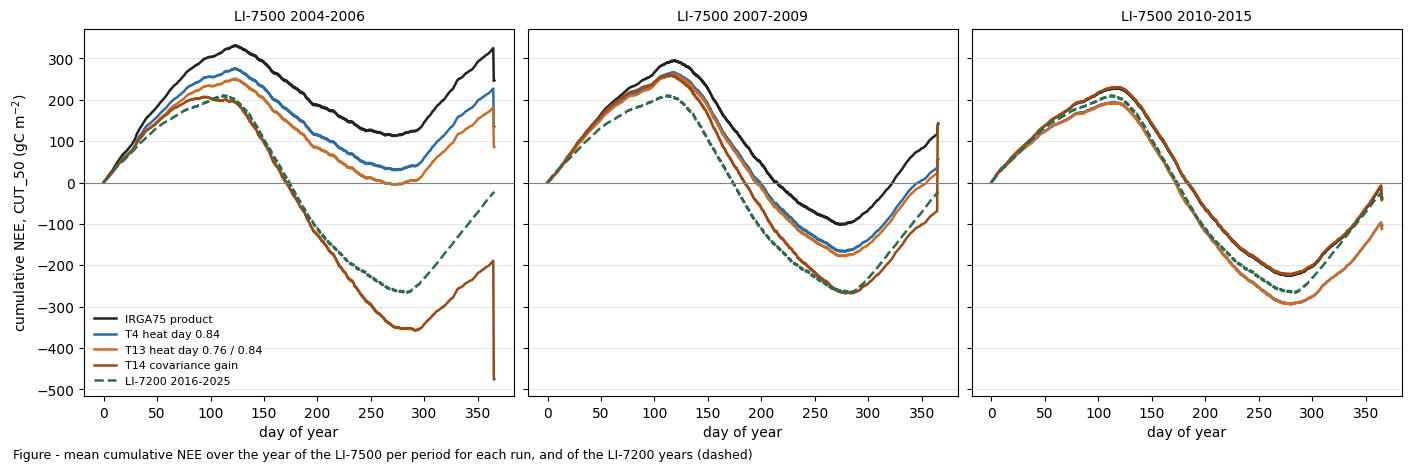

In [9]:
def cumulative(label, years):
    d = DATA[label]
    d = d.loc[d.index.year.isin(list(years)), 'CUT_50'] * UMOL_TO_GC
    c = d.groupby(d.index.year).cumsum()
    doy = np.floor(((d.index.dayofyear - 1) + d.index.hour / 24 + d.index.minute / 1440) * 2) / 2
    return c.groupby(doy).mean()


fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), layout='constrained', sharey=True)
_colors = {'IRGA75 product': '#1F2623', 'T4 heat day 0.84': '#2B6CA3', 'T13 heat day 0.76 / 0.84': '#C96F2B',
           'T14 covariance gain': '#9C4A16'}
_ref_c = cumulative('IRGA72 product', range(REF_YEARS[0], REF_YEARS[1] + 1))
for ax, p in zip(axes, ('2004-2006', '2007-2009', '2010-2015')):
    lo, hi = PERIODS[p]
    for l in TEST_RUNS:
        if l in DATA:
            c = cumulative(l, range(lo, hi + 1))
            ax.plot(c.index, c, lw=1.8, color=_colors[l], label=l)
    ax.plot(_ref_c.index, _ref_c, lw=1.8, color='#2E6A4E', ls='--', label=f'LI-7200 {REF_YEARS[0]}-{REF_YEARS[1]}')
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set_title(f'LI-7500 {p}', fontsize=10)
    ax.set_xlabel('day of year')
    ax.grid(axis='y', color='0.9')
axes[0].set_ylabel('cumulative NEE, CUT_50 (gC m$^{-2}$)')
axes[0].legend(frameon=False, fontsize=8)
figcap(fig, "mean cumulative NEE over the year of the LI-7500 per period for each run, and of the "
            "LI-7200 years (dashed)")
plt.show()

## ⏱️ Runtime

In [10]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}, runtime {datetime.now() - NOTEBOOK_START}")

Finished: 2026-11-08 02:43:33, runtime 0:00:02.918849
